# D2_04 운전 조건 군집 (K-means)

> **오늘 질문:** 정답 없이도, 데이터 속에 숨은 '운전 모드'를 찾을 수 있을까?

운전 조건 4가지(공기 온도, 공정 온도, 회전수, 토크)만으로 비슷한 기록끼리 묶습니다. 고장 여부는 쓰지 않습니다.

| 표시 | 의미 |
|---|---|
| 📋 제공 | 코드가 들어 있습니다. 실행만 하세요 |
| ✍️ 입력 | 설명을 보고 직접 입력하세요 |
| 💬 해석 | 결과를 보고 답을 적어 보세요 |

## 0. 준비 📋

In [1]:
%matplotlib inline
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import koreanize_matplotlib
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

df = pd.read_parquet("../../data/factory_table.parquet")
features = ["air_temp", "process_temp", "rpm", "torque"]

## 1. 표준화 ✍️

K-means는 거리로 묶습니다. 회전수(수천 단위)가 온도(수십 단위)보다 거리를 지배하지 않도록 표준화합니다.

> 변수 이름: `X_scaled`

In [2]:
# 힌트: StandardScaler().fit_transform(데이터)
X_scaled = StandardScaler().fit_transform(df[features])
pd.DataFrame(X_scaled, columns=features).describe().round(2)

,air_temp,process_temp,rpm,torque
count,10000.00,10000.00,10000.00,10000.00
mean,0.00,0.00,-0.00,0.00
std,1.00,1.00,1.00,1.00
min,-2.35,-2.89,-2.07,-3.63
25%,-0.85,-0.80,-0.65,-0.68
50%,0.05,0.07,-0.20,0.01
75%,0.75,0.74,0.41,0.68
max,2.25,2.56,7.51,3.67


## 2. 군집 수(k) 정하기 📋

k를 2~8로 바꿔 가며 **엘보(오차 합)** 와 **실루엣 점수**를 계산합니다. 실루엣은 1만 건 중 2,000건만 뽑아 빠르게 계산합니다.

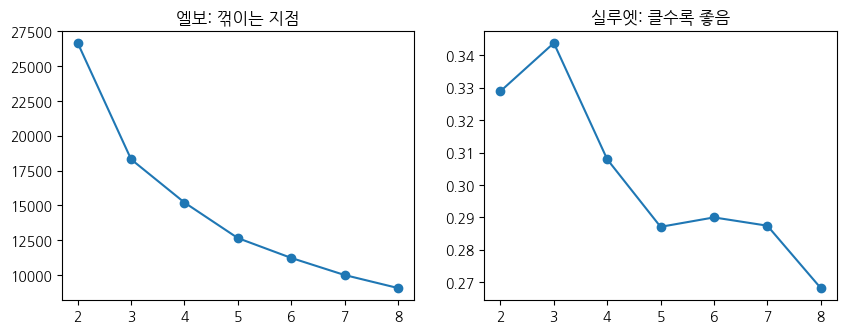

,k,오차합,실루엣
0,2,26663.950,0.329
1,3,18313.267,0.344
2,4,15209.905,0.308
3,5,12658.250,0.287
4,6,11233.982,0.290
5,7,10007.257,0.287
6,8,9073.428,0.268


In [3]:
# UserWarning: Could not find the number of physical cores for the following reason
import os
# os.environ["LOKY_MAX_CPU_COUNT"] = str(os.cpu_count())
os.environ["LOKY_MAX_CPU_COUNT"] = "2"

rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_scaled)
    sil = silhouette_score(X_scaled, km.labels_, sample_size=2000, random_state=42)
    rows.append({"k": k, "오차합": km.inertia_, "실루엣": sil})
scores = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(scores["k"], scores["오차합"], marker="o")
axes[0].set_title("엘보: 꺾이는 지점")
axes[1].plot(scores["k"], scores["실루엣"], marker="o")
axes[1].set_title("실루엣: 클수록 좋음")
plt.show()
scores.round(3)

**Q1.** 몇 개의 군집이 적절해 보이나요? 엘보와 실루엣이 같은 답을 주나요?

> 답:


In [4]:
import mglearn

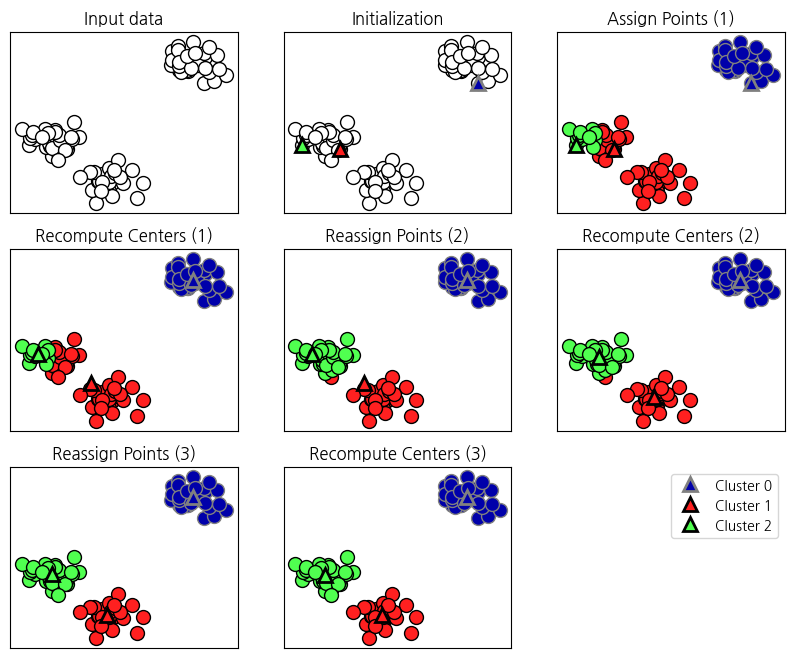

In [5]:
mglearn.plots.plot_kmeans_algorithm()

## 3. k = 3으로 군집 ✍️

`fit_predict()`는 학습과 동시에 각 기록의 군집 번호를 돌려줍니다.

> 변수 이름: `kmeans`, 새 컬럼 `cluster`

In [6]:
# 힌트: KMeans(n_clusters=3, n_init=10, random_state=42), 모델.fit_predict(데이터)
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
df['cluster'] = kmeans.fit_predict(X_scaled)
df['cluster'].value_counts().sort_index()

cluster
0    3928
1    4004
2    2068
Name: count, dtype: int64

## 4. 군집을 눈으로 확인 ✍️

회전수–토크, 공기 온도–토크 두 장으로 군집이 어떻게 나뉘었는지 봅니다.

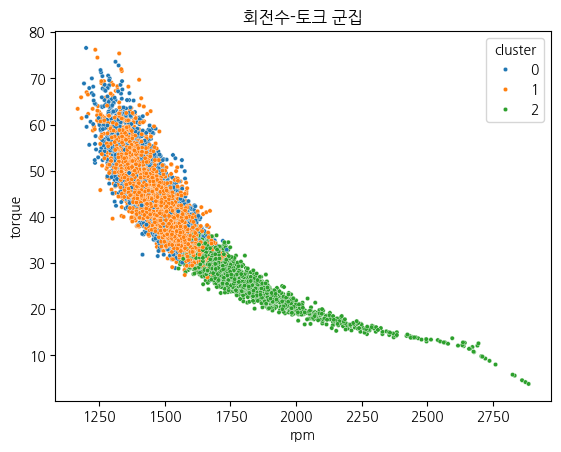

In [7]:
# 힌트: sns.scatterplot(..., hue="cluster", palette="tab10", s=10)
sns.scatterplot(data=df, x='rpm', y='torque', hue='cluster', palette="tab10", s=10)
plt.title("회전수-토크 군집")
plt.show()

## 정리 💬

**Q2.** 두 산점도를 보고 세 군집이 각각 무엇으로 나뉜 것 같은지 한 줄씩 적어 보세요.

> 답:
